c:\Users\chall\anaconda3\envs\tf_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


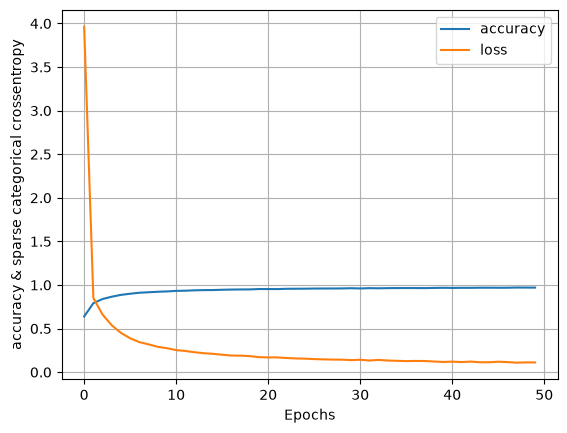

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.96      0.97      1032
           3       0.95      0.97      0.96      1010
           4       0.98      0.97      0.97       982
           5       0.97      0.96      0.96       892
           6       0.98      0.98      0.98       958
           7       0.98      0.97      0.98      1028
           8       0.94      0.95      0.94       974
           9       0.97      0.95      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000

perfomed well!
model accuracy:97.06%




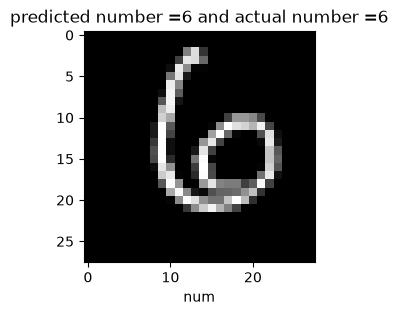

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report,accuracy_score
import tensorflow as tf

# Loading the MNIST handwritten digit dataset
# It contains 60,000 training images and 10,000 testing images by default
# Each image is a 28x28 grayscale image of a handwritten digit (0-9)

sets=tf.keras.datasets.mnist.load_data()
(x_train,y_train),(x_test,y_test)=sets

x_test_set2=x_test
x_train=x_train.reshape(-1,784)
x_test=x_test.reshape(-1,784)


model=tf.keras.Sequential([

    # First hidden layer with 128 neurons
   # ReLU activation introduces non-linearity
   # Each neuron receives 784 input features
   
   tf.keras.layers.Dense(128,activation='relu',input_shape=(784,)),

   tf.keras.layers.Dropout(0.2),  # this randomnly disables 20 percentage of neurons during training

   tf.keras.layers.Dense(128,activation='relu'), #second hidden layer 
   tf.keras.layers.Dropout(0.2),

  # Output layer with 10 neurons representing digits 0 to 9
# Softmax converts the outputs into probabilities

   tf.keras.layers.Dense(10,activation='softmax')

])

# function to plot accuracy, loss  

def plot_history(data):         
    plt.plot(data.history['accuracy'],label='accuracy')
    plt.plot(data.history['loss'],label='loss')
    plt.xlabel('Epochs')
    plt.ylabel('accuracy & sparse categorical crossentropy')
    plt.legend()
    plt.grid(True)
    plt.show()

#compiles neural network

model.compile(

    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), #adam optimizer updates the wights making losses minimum
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Training the neural network
# x_train contains input images and y_train contains their actual labels
# epochs=50 means the entire training dataset is processed 50 times
# batch_size=128 means 128 samples are processed in each batch
# verbose=0 suppresses the training progress output

data=model.fit(x_train,y_train,epochs=50,batch_size=128,verbose=0)

num=int(input("enter the num between 0 and 9999:"))

plot_history(data)  

# Using the trained model to predict the labels of test images
# The output contains 10 probabilities for each image

prediction=model.predict(x_test)


# finding index of highest probability.This gives the predicted digit (0-9) for each test image

prediction=np.argmax(prediction,axis=1)

# generates classification report which contains precision, recall,F1-score

print(classification_report(y_test,prediction))

accuracy=accuracy_score(y_test,prediction)*100

if(accuracy < 80):
   print(f"less than expected accuracy of the trained model:{accuracy}%")
else:
   print("perfomed well!")
   print(f"model accuracy:{accuracy}%")


print("\n")

plt.figure(figsize=(13,3))
plt.imshow(x_test_set2[num],cmap='gray')
plt.xlabel("num")

if prediction[num] == y_test[num]:
   plt.title(f"predicted number ={prediction[num]} and actual number ={y_test[num]}")
else:
   plt.title(f"predicted number ={prediction[num]} and actual number ={y_test[num]}")
plt.show()
